# Horse Colic Survival Prediction

## Introduction

Colic (abdominal pain) is a serious and potentially fatal condition in horses. This notebook prepares the data, explores it and selects the model behind a web service that estimates, from the information available on admission, the probability that a horse with colic will survive.

- **Dataset:** training data from the Kaggle competition [Predict Health Outcomes of Horses](https://www.kaggle.com/competitions/playground-series-s3e22) (Playground Series S3E22), a synthetic dataset derived from the [UCI Horse Colic dataset](https://archive.ics.uci.edu/dataset/47/horse+colic). The data is not included in the repository; see the README for download instructions.
- **Target:** `lived` versus `not lived` (`died` + `euthanized`).
- **Metric:** ROC AUC, because the service returns a probability and AUC measures how well the model ranks horses regardless of the decision threshold. Accuracy and F1 are reported as supporting metrics.

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, mutual_info_score

import seaborn as sns



In [2]:
# Seed: pass SEED as random_state to every split and model
SEED = 42
np.random.seed(SEED)

In [3]:
# Load the dataset
df = pd.read_csv('data/train.csv')

print(f"{df.shape[0]} rows and {df.shape[1]} columns in the dataset.")
print(f"\n{df.head()}")

1235 rows and 29 columns in the dataset.

   id surgery    age  hospital_number  rectal_temp  pulse  respiratory_rate  \
0   0     yes  adult           530001         38.1  132.0              24.0   
1   1     yes  adult           533836         37.5   88.0              12.0   
2   2     yes  adult           529812         38.3  120.0              28.0   
3   3     yes  adult          5262541         37.1   72.0              30.0   
4   4      no  adult          5299629         38.0   52.0              48.0   

  temp_of_extremities peripheral_pulse mucous_membrane  ...  \
0                cool          reduced   dark_cyanotic  ...   
1                cool           normal   pale_cyanotic  ...   
2                cool          reduced       pale_pink  ...   
3                cold          reduced       pale_pink  ...   
4              normal           normal     normal_pink  ...   

  packed_cell_volume total_protein abdomo_appearance abdomo_protein  \
0               57.0           8.

## Objective

The original `outcome` column has three values: `lived`, `died` and `euthanized`. The service estimates survival, and euthanasia is partly a human decision rather than a purely clinical outcome, so `died` and `euthanized` are grouped into a single class. The new binary target is `lived` (1 = lived, 0 = not lived).

In [4]:
df["lived"] = np.where(df["outcome"] == "lived", 1, 0)
del df["outcome"]

Percentage of horses that lived: 46.48%
Percentage of horses that did not live: 53.52%



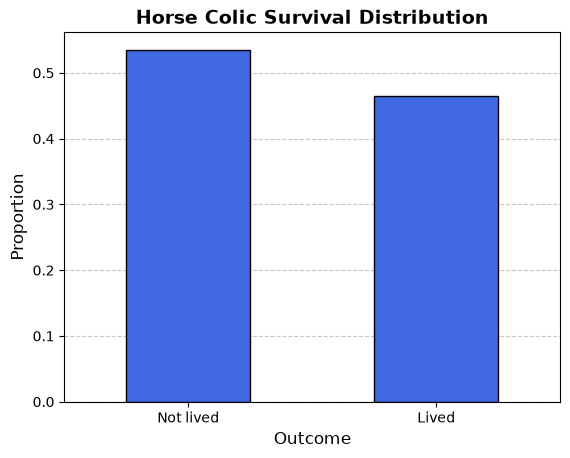

In [5]:
lived = df["lived"].value_counts(normalize=True)

print(f"Percentage of horses that lived: {lived[1]:.2%}")
print(f"Percentage of horses that did not live: {lived[0]:.2%}")
print("")

lived.plot(kind='bar', color='royalblue', edgecolor='black', zorder=2)

plt.title('Horse Colic Survival Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Outcome', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=1)
plt.xticks(ticks=[0, 1], labels=['Not lived', 'Lived'], rotation=0)

plt.show()

**Conclusion:** 46.5% of the horses lived and 53.5% did not. The classes are nearly balanced, so no resampling is needed and accuracy remains easy to interpret. A model that always predicts "not lived" already reaches 53.5% accuracy: this is the baseline the models must beat.

## Cleaning

Cleaning decisions:

1. **Groups:** `hospital_number` is kept aside as `groups` before dropping it, because it is used later to split the data by groups (see the `hospital_number` analysis).
2. **Excluded columns:**
   - `id` and `hospital_number` are identifiers.
   - `cp_data` has no significance according to UCI.
   - `surgical_lesion`, `lesion_1`, `lesion_2` and `lesion_3` are only known after surgery or autopsy, so they would leak future information.
3. **Missing values:** the CSV stores them as the text `None`, which pandas reads as missing. All of them are in categorical columns. They are filled with `"unknown"` as a category of their own, because a test that was not done may itself be informative (analysed in the EDA). This value is different from lowercase `none`, a valid category in columns such as `abdominal_distention`. The numerical columns have no missing values, so they are not imputed; the API will require them.
4. **Rare categories:** five values appear in only one or two rows. They are artefacts of the synthetic generation, so a model cannot learn from them and the API should not accept them:
   - `capillary_refill_time = "3"` is read as a refill time of 3 seconds, which UCI groups with longer times, so it becomes `"more_3_sec"`.
   - `pain = "slight"` is closest to `"mild_pain"`.
   - `nasogastric_reflux = "slight"` is closest to `"less_1_liter"`.
   - `peristalsis = "distend_small"` and `rectal_exam_feces = "serosanguious"` belong to other columns (`abdomen` and `abdomo_appearance`), so they become `"unknown"`.
5. **`total_protein` units:** the values form two separate groups, 3.5–13 and 46–89, with nothing in between. Normal values are around 6–7.5 g/dL, so the high group is most likely in g/L. Values above 30, the middle of the gap, are divided by 10.

In [6]:
groups = df["hospital_number"]

cols_to_drop = ["id", "hospital_number", "cp_data", "surgical_lesion", "lesion_1", "lesion_2", "lesion_3"]
df = df.drop(columns=cols_to_drop)

print(df.shape)

(1235, 22)


In [7]:
categorical_columns = df.select_dtypes(include=['object', 'string']).columns.tolist()
numerical_columns = [c for c in df.select_dtypes(include='number').columns if c != 'lived']

print(f"Categorical columns: {categorical_columns}")
print(f"Numerical columns: {numerical_columns}")

Categorical columns: ['surgery', 'age', 'temp_of_extremities', 'peripheral_pulse', 'mucous_membrane', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distention', 'nasogastric_tube', 'nasogastric_reflux', 'rectal_exam_feces', 'abdomen', 'abdomo_appearance']
Numerical columns: ['rectal_temp', 'pulse', 'respiratory_rate', 'nasogastric_reflux_ph', 'packed_cell_volume', 'total_protein', 'abdomo_protein']


In [8]:
print(f"Total number of missing values: {df.isna().sum().sum()}")

df[categorical_columns] = df[categorical_columns].fillna('unknown')

print(f"Total number of missing values after imputation: {df.isna().sum().sum()}")

Total number of missing values: 765
Total number of missing values after imputation: 0


In [9]:
# Value counts of each categorical column, to spot rare categories
for c in categorical_columns:
    print(c, df[c].value_counts().to_dict())

surgery {'yes': 887, 'no': 348}
age {'adult': 1160, 'young': 75}
temp_of_extremities {'cool': 700, 'normal': 324, 'cold': 121, 'warm': 51, 'unknown': 39}
peripheral_pulse {'reduced': 724, 'normal': 429, 'unknown': 60, 'absent': 18, 'increased': 4}
mucous_membrane {'pale_pink': 284, 'normal_pink': 260, 'pale_cyanotic': 250, 'bright_red': 211, 'dark_cyanotic': 121, 'bright_pink': 88, 'unknown': 21}
capillary_refill_time {'less_3_sec': 834, 'more_3_sec': 393, 'unknown': 6, '3': 2}
pain {'depressed': 429, 'mild_pain': 408, 'severe_pain': 146, 'extreme_pain': 120, 'alert': 87, 'unknown': 44, 'slight': 1}
peristalsis {'hypomotile': 664, 'absent': 444, 'normal': 53, 'hypermotile': 53, 'unknown': 20, 'distend_small': 1}
abdominal_distention {'moderate': 543, 'slight': 346, 'none': 212, 'severe': 111, 'unknown': 23}
nasogastric_tube {'slight': 758, 'none': 275, 'significant': 122, 'unknown': 80}
nasogastric_reflux {'more_1_liter': 604, 'none': 331, 'less_1_liter': 278, 'unknown': 21, 'slight': 

In [10]:
# Rare categories (1-2 rows each), artefacts of the synthetic generation
rare_categories = {
    "capillary_refill_time": {"3": "more_3_sec"},
    "pain": {"slight": "mild_pain"},
    "nasogastric_reflux": {"slight": "less_1_liter"},
    "peristalsis": {"distend_small": "unknown"},
    "rectal_exam_feces": {"serosanguious": "unknown"},
}
df = df.replace(rare_categories)

# Smallest category of each column after the replacement
print({c: int(df[c].value_counts().min()) for c in categorical_columns})

{'surgery': 348, 'age': 75, 'temp_of_extremities': 39, 'peripheral_pulse': 4, 'mucous_membrane': 21, 'capillary_refill_time': 6, 'pain': 44, 'peristalsis': 21, 'abdominal_distention': 23, 'nasogastric_tube': 80, 'nasogastric_reflux': 21, 'rectal_exam_feces': 49, 'abdomen': 33, 'abdomo_appearance': 48}


Rows converted from g/L to g/dL: 280
Range after conversion: 3.5 - 13.0


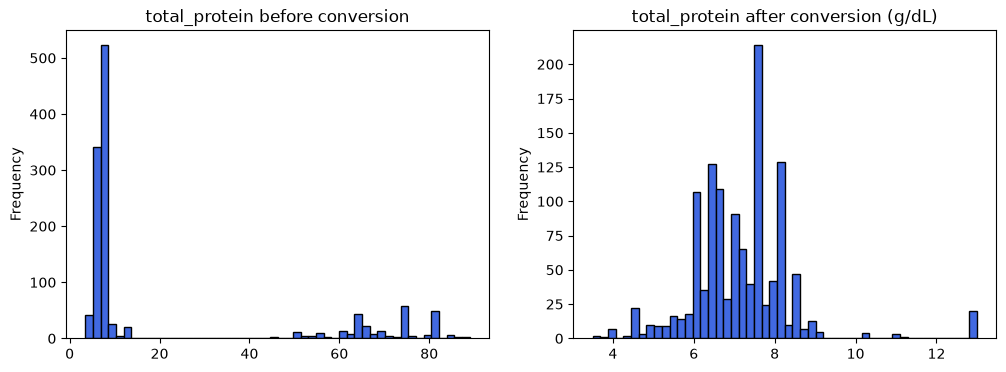

In [11]:
# total_protein mixes g/dL and g/L: no values between 13 and 46
PROTEIN_THRESHOLD = 30

protein_before = df["total_protein"].copy()
df.loc[df["total_protein"] > PROTEIN_THRESHOLD, "total_protein"] /= 10

print(f"Rows converted from g/L to g/dL: {(protein_before > PROTEIN_THRESHOLD).sum()}")
print(f"Range after conversion: {df['total_protein'].min()} - {df['total_protein'].max()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
protein_before.plot(kind='hist', bins=50, ax=axes[0], color='royalblue', edgecolor='black')
axes[0].set_title('total_protein before conversion')
df["total_protein"].plot(kind='hist', bins=50, ax=axes[1], color='royalblue', edgecolor='black')
axes[1].set_title('total_protein after conversion (g/dL)')
plt.show()

**Conclusion:** after cleaning, the dataset has 1,235 rows, 21 features (14 categorical and 7 numerical) and no missing values. Missing categorical values are kept as `"unknown"`, the five rare categories are merged into existing ones, and the 280 `total_protein` values in g/L are converted to g/dL, so the column now has a single, clinically plausible range.

## Hospital_number analysis

According to UCI, `hospital_number` is the case number assigned to a horse, not a hospital. In this synthetic dataset, however, the same value appears in many rows. This section checks how often values repeat and whether rows that share a value also share an outcome.

In [12]:
counts = groups.value_counts()

print(f"Number of unique hospital numbers: {groups.nunique()}")
print(f"hospital_number values that repeat: {(counts > 1).sum()}")
print(f"Minimum number of rows per hospital number: {counts.min()}")
print(f"Maximum number of rows per hospital number: {counts.max()}")

Number of unique hospital numbers: 255
hospital_number values that repeat: 198
Minimum number of rows per hospital number: 1
Maximum number of rows per hospital number: 46


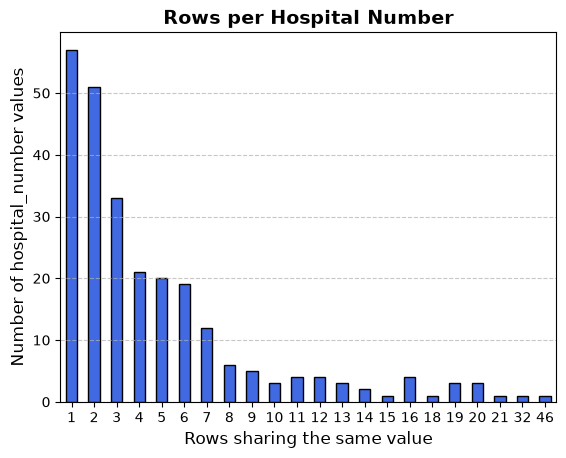

In [13]:
counts.value_counts().sort_index().plot(kind='bar', color='royalblue', edgecolor='black')

plt.title('Rows per Hospital Number', fontsize=14, fontweight='bold')
plt.xlabel('Rows sharing the same value', fontsize=12)
plt.ylabel('Number of hospital_number values', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=1)
plt.xticks(rotation=0)

plt.show()

In [14]:
mixed = df.groupby(groups)["lived"].nunique()

print(f"hospital_number values with mixed outcomes: {(mixed > 1).sum()}")

hospital_number values with mixed outcomes: 152


**Conclusion:** there are only 255 distinct `hospital_number` values for 1,235 rows; 198 of them repeat, one up to 46 times. In 152 of these groups some horses lived and others did not, so a repeated value does not necessarily mean the same horse: the rows are probably synthetic variations of the same original case. If rows from the same group ended up in both training and validation, the model could recognise near-copies and the metrics would be optimistic. For that reason, every split in this notebook is grouped by `hospital_number`.

## Train, validation, and test split

The competition also provides a `test.csv` file, but it has no `outcome` column: its labels are hidden because it is used to score Kaggle submissions. Without labels it cannot be used to evaluate the model, so all three sets are taken from `train.csv`.

The data is split into train (60%), validation (20%) and test (20%) with `StratifiedGroupKFold`, which keeps the class proportions and puts every `hospital_number` value entirely in one of the three sets:

1. 20% of the rows are held out as the test set.
2. A quarter of the remaining 80% (20% of the total) becomes the validation set.

Models are trained on train and compared on validation. The test set is not used until the final evaluation.

In [15]:
y = df["lived"]

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

full_idx, test_idx = next(outer.split(df, y, groups))
df_full_train = df.iloc[full_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

groups_full_train = groups.iloc[full_idx].reset_index(drop=True)
groups_test = groups.iloc[test_idx].reset_index(drop=True)


In [16]:
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)

train_idx, val_idx = next(inner.split(df_full_train, df_full_train["lived"], groups_full_train))
df_train = df_full_train.iloc[train_idx].reset_index(drop=True)
df_val = df_full_train.iloc[val_idx].reset_index(drop=True)

groups_train = groups_full_train.iloc[train_idx].reset_index(drop=True)
groups_val = groups_full_train.iloc[val_idx].reset_index(drop=True)



In [17]:
y_test = df_test["lived"]
y_full_train = df_full_train["lived"]
y_train = df_train["lived"]
y_val = df_val["lived"]

del df_test["lived"]
del df_full_train["lived"]
del df_train["lived"]
del df_val["lived"]

In [18]:
split_summary = pd.DataFrame({
    "Set": ["train", "val", "test"],
    "Rows": [df_train.shape[0], df_val.shape[0], df_test.shape[0]],
    "Share": [df_train.shape[0] / df.shape[0], df_val.shape[0] / df.shape[0], df_test.shape[0] / df.shape[0]],
    "lived": [y_train.mean(), y_val.mean(), y_test.mean()]
})

print(split_summary.round(3))

print("\nOverlapping groups:")
print(f"Train-Val: {len(set(groups_train) & set(groups_val))}, Train-Test: {len(set(groups_train) & set(groups_test))}, Val-Test: {len(set(groups_val) & set(groups_test))}")

     Set  Rows  Share  lived
0  train   740  0.599  0.466
1    val   248  0.201  0.464
2   test   247  0.200  0.462

Overlapping groups:
Train-Val: 0, Train-Test: 0, Val-Test: 0


**Conclusion:** the split gives 740 rows for training, 248 for validation and 247 for testing (60/20/20). The share of horses that lived is almost the same in the three sets (46.6%, 46.4% and 46.2%), and no `hospital_number` value appears in more than one set, so validation and test only contain unseen groups.

## EDA

## Validation and surgery

## Models

## Comparison of models and selection of the best one

## Evaluation of the best model

## Conclusions